# 1. Abstract

This research work aimed to predict whether people have trouble sleeping (Trouble Sleeping) and identify the main factors affecting it. The study used a database containing a total of 647 data, and after pre-processing such as data cleaning and deduplication, 4 types of Machine Learning algorithms were used: k-Nearest Neighbors, Random Forest, Logistic Regression, and Support Vector Machine. The performance of the models was tested on three different Train/Test partitions of 95:5, 85:15, and 75:25, and compared using Accuracy, Precision, Recall, and F1-Score indicators.

From the results of the study, the Logistic Regression model was determined to be the most suitable model for predicting whether people have trouble sleeping because it performed more stably and with higher accuracy (Accuracy ~90%) than other algorithms. In addition, the accuracy was improved to 90.52% by optimizing the model parameters using the GridSearchCV method.

Finally, the top 5 factors most likely to influence the likelihood of sleep difficulties were identified by determining Feature Importance. Notably, demographic factors, particularly Hispanic/Latino (Race_4), emerged as the most influential predictor. Other key factors included treatment and medication use, employment, sleep medication, and physical health. These results suggest that there is a need for targeted health care and support for specific population groups experiencing sleep difficulties.

(Race_4 (Hispanic/Latino):
This result is directly linked to the characteristics of the dataset, aside from real-world social factors. EDA revealed a highly imbalanced distribution, where the majority group (Category 1) has over 500 participants, while Race_4 comprises fewer than 50. Machine learning models are highly sensitive to patterns within small sample sizes, which can cause the algorithm to disproportionately highlight minority groups as the highest influential predictors. In other words, the extreme data imbalance may have artificially inflated the influence of this specific group.)

Keywords: Machine Learning, Sleep Difficulty, Logistic Regression, Hyperparameter Tuning, Feature Importance, Demographic Factors.

# 1. Characterization of Data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns #visualisation
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

In [2]:
df= pd.read_csv('NPHA-doctor-visits.csv')

In [3]:
#  Target=Trouble Sleeping (0,1)
df['Trouble Sleeping'] = df['Trouble Sleeping'].apply(lambda x: 1 if x > 1 else 0)
print("Trouble Sleeping:", df['Trouble Sleeping'].unique())

Trouble Sleeping: [1 0]


* In the original CSV data, the Trouble Sleeping column had values like 1, 2, and 3. However, your goal is to answer a simple "Yes or No" question: "Does the person have trouble sleeping?" (Binary Classification). The Machine Learning model only understands 0 and 1. So, we combine values 2 and 3 into 1 (Yes), and we change value 1 into 0 (No).

In [4]:
df.head(5)

,Number of Doctors Visited,Age,Phyiscal Health,Mental Health,Dental Health,Employment,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Bathroom Needs Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Trouble Sleeping,Prescription Sleep Medication,Race,Gender
0,3,2,4,3,3,3,0,0,0,0,1,1,3,1,2
1,2,2,4,2,3,3,1,0,0,1,0,1,3,1,1
2,3,2,3,2,3,3,0,0,0,0,1,1,3,4,1
3,1,2,3,2,3,3,0,0,0,1,0,1,3,4,2
4,3,2,3,3,3,3,1,0,0,0,0,1,3,1,2


In [5]:
df.tail(5)

,Number of Doctors Visited,Age,Phyiscal Health,Mental Health,Dental Health,Employment,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Bathroom Needs Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Trouble Sleeping,Prescription Sleep Medication,Race,Gender
709,2,2,2,2,2,3,0,0,0,1,0,1,3,1,1
710,3,2,2,2,2,2,1,0,0,0,1,1,3,1,2
711,3,2,4,2,3,3,0,0,0,0,0,1,3,1,1
712,3,2,3,1,3,3,1,0,1,1,1,1,3,1,2
713,2,2,3,2,2,1,1,0,1,1,0,1,3,1,1


* The table shows a sample of the last 5 records of 14 features, giving us a quick look at the format and values ccontained within the dtaset.

In [6]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 714 entries, 0 to 713
Data columns (total 15 columns):
 #   Column                                      Non-Null Count  Dtype
---  ------                                      --------------  -----
 0   Number of Doctors Visited                   714 non-null    int64
 1   Age                                         714 non-null    int64
 2   Phyiscal Health                             714 non-null    int64
 3   Mental Health                               714 non-null    int64
 4   Dental Health                               714 non-null    int64
 5   Employment                                  714 non-null    int64
 6   Stress Keeps Patient from Sleeping          714 non-null    int64
 7   Medication Keeps Patient from Sleeping      714 non-null    int64
 8   Pain Keeps Patient from Sleeping            714 non-null    int64
 9   Bathroom Needs Keeps Patient from Sleeping  714 non-null    int64
 10  Uknown Keeps Patient from Sleeping          714 n

* Missing Values is nothing in the dataset

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Number of Doctors Visited,714.0,2.112045,0.683441,1.0,2.0,2.0,3.0,3.0
Age,714.0,2.000000,0.000000,2.0,2.0,2.0,2.0,2.0
Phyiscal Health,714.0,2.794118,0.900939,-1.0,2.0,3.0,3.0,5.0
Mental Health,714.0,1.988796,0.939928,-1.0,1.0,2.0,3.0,5.0
Dental Health,714.0,3.009804,1.361117,-1.0,2.0,3.0,4.0,6.0
Employment,714.0,2.806723,0.586582,1.0,3.0,3.0,3.0,4.0
Stress Keeps Patient from Sleeping,714.0,0.247899,0.432096,0.0,0.0,0.0,0.0,1.0
Medication Keeps Patient from Sleeping,714.0,0.056022,0.230126,0.0,0.0,0.0,0.0,1.0
Pain Keeps Patient from Sleeping,714.0,0.218487,0.413510,0.0,0.0,0.0,0.0,1.0
Bathroom Needs Keeps Patient from Sleeping,714.0,0.504202,0.500333,0.0,0.0,1.0,1.0,1.0


* Number of Doctors Visited, Physical Health, Mental Health, Employment, Prescription Sleep Medication: The minimum value for these columns is -1. Since health and doctor visits cannot have negative values, these are likely data errors or missing codes (because the isnull() test returned a null value of 0).
* Race and Gender: Although they appear as int64 (numeric) in the dtypes section, these are essentially categorical variables. Gender has values of 1 and 2 (mean 1.55), and Race has values of 1 to 5.
* Distribution and Mean:
* Mental Health: has values of -1 to 5, mean 1.98.
* Stress Keeps Patient from Sleeping, Medication Keeps, Pain Keeps, Bathroom Needs, Unknown Keeps: These are columns that have values of 0 or 1 (logical values of Yes/No). For example, the mean of the Medication Keeps Patient. column is 0.05, indicating that very few people (~35 out of 714) are having trouble sleeping because they are not taking their medication.
* Trouble Sleeping: The mean is 0.91, indicating that the majority of respondents (91%) have trouble sleeping.
Overall Conclusion:
The data is clean (empty) but the Age column has incorrect values and some columns contain negative values of -1. In the next "Data Pre-processing" step, these -1 values need to be converted to null values (NaN) or the data type needs to be changed to the correct one (e.g., Race, Gender as categories)

# 2. Data Pre-processing

In [8]:
df.isnull().sum()

Number of Doctors Visited                     0
Age                                           0
Phyiscal Health                               0
Mental Health                                 0
Dental Health                                 0
Employment                                    0
Stress Keeps Patient from Sleeping            0
Medication Keeps Patient from Sleeping        0
Pain Keeps Patient from Sleeping              0
Bathroom Needs Keeps Patient from Sleeping    0
Uknown Keeps Patient from Sleeping            0
Trouble Sleeping                              0
Prescription Sleep Medication                 0
Race                                          0
Gender                                        0
dtype: int64

* This code represents the number of empty or missing values (Null/NaN) for each column in the DataFrame.

In [9]:
# . Hidden missing values ('?', 'Na', 'UnKnown') to NaN
hidden = ['?', 'Na', 'UnKnown']
text_cols = [c for c in df.select_dtypes(include=['object', 'str']).columns if c != 'Target']

nan_before = df.isnull().sum().sum()
for col in text_cols:
    n = df[col].isin(hidden).sum()
    if n > 0:
        print(f"{col}: {n} hidden missing values")

df[text_cols] = df[text_cols].replace(hidden, np.nan)

nan_after = df.isnull().sum().sum()
print(f"\nMissing values before: {nan_before}")
print(f"Missing values after:  {nan_after}")
print(f"Newly revealed hidden missing values: {nan_after - nan_before}")


Missing values before: 0
Missing values after:  0
Newly revealed hidden missing values: 0


* This code searches for "hidden missing values" ('?', 'Na', 'Unknown') that are in text format (string/object) within the dataset and replaces them with the standard missing value, NaN (Not a Number). However, no hidden values were detected. In other words, the data is clean.

In [10]:
hidden = ['?', 'Na', 'UnKnown']
remaining = {c: int(df[c].isin(hidden).sum()) for c in text_cols if df[c].isin(hidden).sum() > 0}
print("Hidden values remaining:", remaining)     
print("Total NaN:", df.isnull().sum().sum())   

Hidden values remaining: {}
Total NaN: 0


* The database is completely clean of null values ​​and ready for further analysis and input into machine learning models.

In [11]:
df.duplicated().sum()

np.int64(67)

A total of 67 duplicate rows were detected in the dataset.

In [12]:
df = df.drop_duplicates()
print(df.duplicated().sum()) 
print(df.shape)             

0
(647, 15)


* After removing and cleaning the duplicate rows, a total of 647 rows and 15 columns remain. The data is now completely cleaned of duplicates and is ready for further analysis.

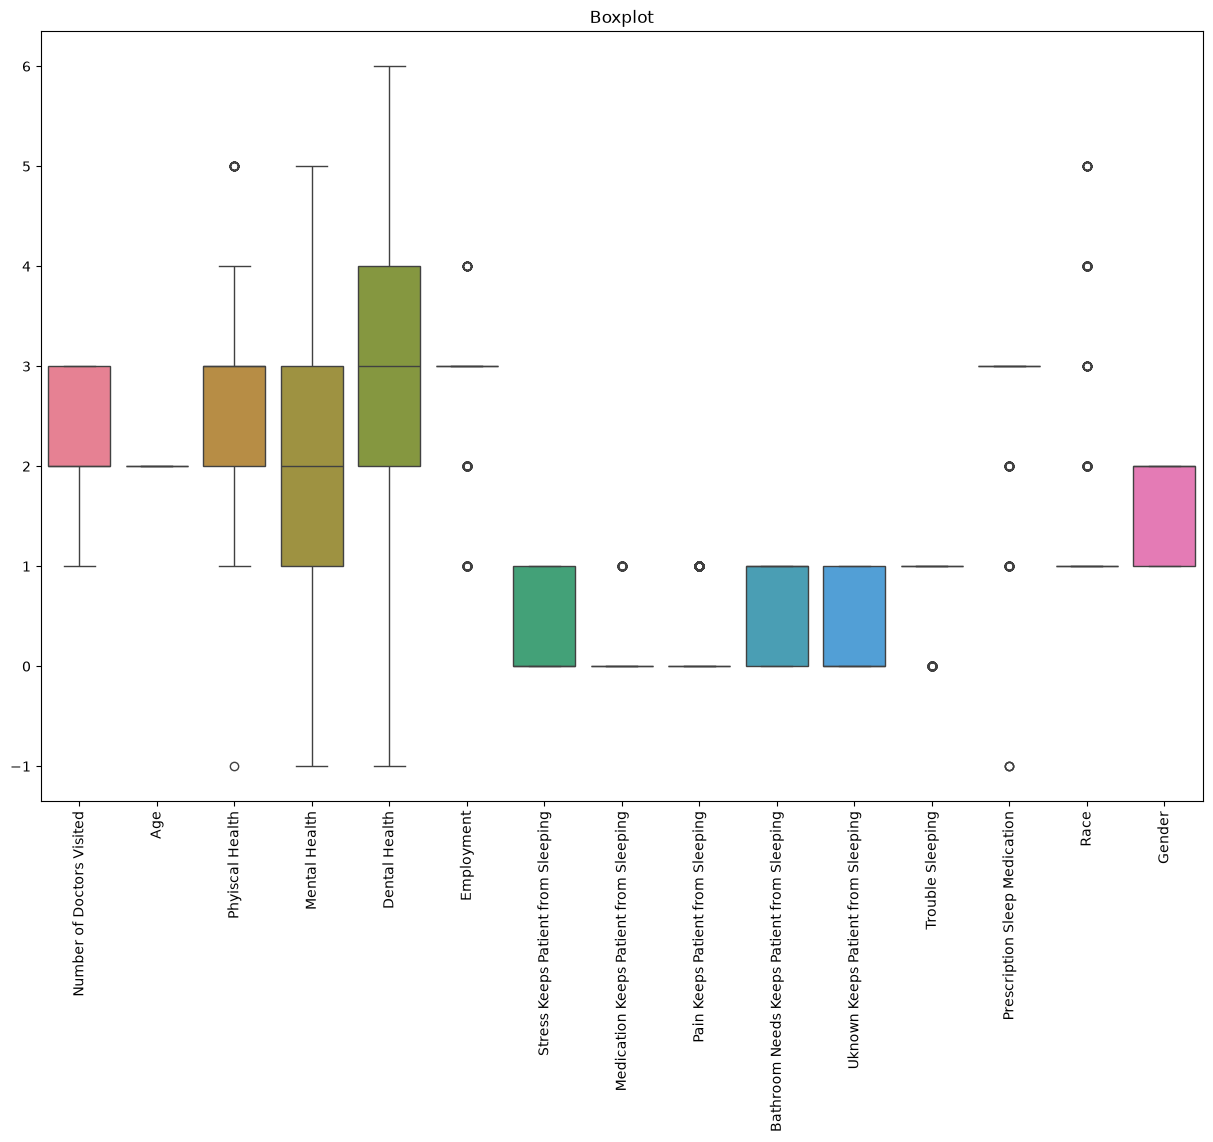

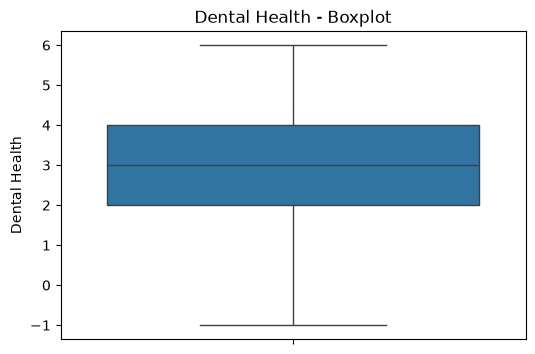

In [13]:
# 1 Outliers detection
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))
sns.boxplot(data=df)
plt.xticks(rotation=90) 
plt.title("Boxplot")
plt.show()
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['Dental Health'])
plt.title("Dental Health - Boxplot")
plt.show()

In [14]:
df_cleaned = df.copy() 
# check outliers columns
cols_to_check = ['Age', 'Physical Health', 'Mental Health', 'Dental Health']

* General Boxplot (Top Chart):
	• The chart shows outliers marked as circles (o) in most columns.
	• Columns like Physical Health, Mental Health, Employment, and Prescription Sleep Medication have values down to -1. These -1 values are showing up as outliers at the bottom of the boxes. (As mentioned earlier, these could be special codes for "not answered").
	• For binary columns (Yes/No, 0/1) like Stress Keeps..., the boxes appear as thin lines, which is normal, but some 1s appear as outliers.
* Dental Health Boxplot (Bottom Chart):
	• Focusing on Dental Health, the median is around 3.
	• Most of the data falls between 2 and 4.
	• There is a clear outlier at -1 at the bottom, and the upper whisker extends to 6. 
Overall Conclusion:
It is clear that there are outliers in the dataset. The negative values (-1) in particular could negatively impact model performance, so the next step should involve handling these outliers (either by removing them or imputing them with correct values).


In [15]:
import numpy as np
df_cleaned.replace(-1, np.nan, inplace=True)
print("How many NaN:")
print(df_cleaned.isnull().sum())

df_cleaned.fillna(df_cleaned.mean(), inplace=True)
print(df_cleaned.isnull().sum()) # 0 

How many NaN:
Number of Doctors Visited                      0
Age                                            0
Phyiscal Health                                1
Mental Health                                 10
Dental Health                                  4
Employment                                     0
Stress Keeps Patient from Sleeping             0
Medication Keeps Patient from Sleeping         0
Pain Keeps Patient from Sleeping               0
Bathroom Needs Keeps Patient from Sleeping     0
Uknown Keeps Patient from Sleeping             0
Trouble Sleeping                               0
Prescription Sleep Medication                  3
Race                                           0
Gender                                         0
dtype: int64
Number of Doctors Visited                     0
Age                                           0
Phyiscal Health                               0
Mental Health                                 0
Dental Health                                 

* The -1 values were removed and replaced with the mean value to clean the data, and the negative values were eliminated.

In [16]:
# remove each column outlier
for col in cols_to_check:
    if col in df_cleaned.columns:
        Q1 = df_cleaned[col].quantile(0.25)
        Q3 = df_cleaned[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & (df_cleaned[col] <= upper_bound)]

print("Rows before removal:", df.shape[0])
print("Rows after removal:", df_cleaned.shape[0])

Rows before removal: 647
Rows after removal: 647


* Because the variance (spread) in the data is very small, the amount of data was not reduced.

In [17]:
df_cleaned.to_csv('cleaned_dataset.csv', index=False)
print("cleaned_data")

cleaned_data


In [18]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# (Gender)Label Encoding
le = LabelEncoder()
df_cleaned['Gender'] = le.fit_transform(df_cleaned['Gender'])

# (Race)One-Hot Encoding 
df_cleaned = pd.get_dummies(df_cleaned, columns=['Race'], drop_first=True)

print("After Encoding :")
print(df_cleaned.columns.tolist())

After Encoding :
['Number of Doctors Visited', 'Age', 'Phyiscal Health', 'Mental Health', 'Dental Health', 'Employment', 'Stress Keeps Patient from Sleeping', 'Medication Keeps Patient from Sleeping', 'Pain Keeps Patient from Sleeping', 'Bathroom Needs Keeps Patient from Sleeping', 'Uknown Keeps Patient from Sleeping', 'Trouble Sleeping', 'Prescription Sleep Medication', 'Gender', 'Race_2', 'Race_3', 'Race_4', 'Race_5']


* This code is designed to convert categorical (text-based) values into numerical values (Encoding) to prepare the data for a machine learning model. Since machine learning algorithms only work with numerical data, this step is mandatory.
* LabelEncoder for the Gender column: Used because it has only 2 unique values, and converting them into simple numbers like 0 and 1 is sufficient. This does not imply any mathematical "order" (like greater than or less than) between the values.
* One-Hot Encoding (pd.get_dummies) for the Race column: If the Race column were converted directly into numbers, the machine might incorrectly assume "3 is greater than 1." Therefore, the get_dummies function splits this column into separate binary columns (like Race_2, Race_3, etc.), representing a person's category membership with 1s and 0s. (drop_first=True removes the first column to prevent multicollinearity). 
Conclusion:
This code is the most crucial preprocessing step to maintain model accuracy and allow the machine to understand the data without distorting its mathematical meaning.

# 3.EDA

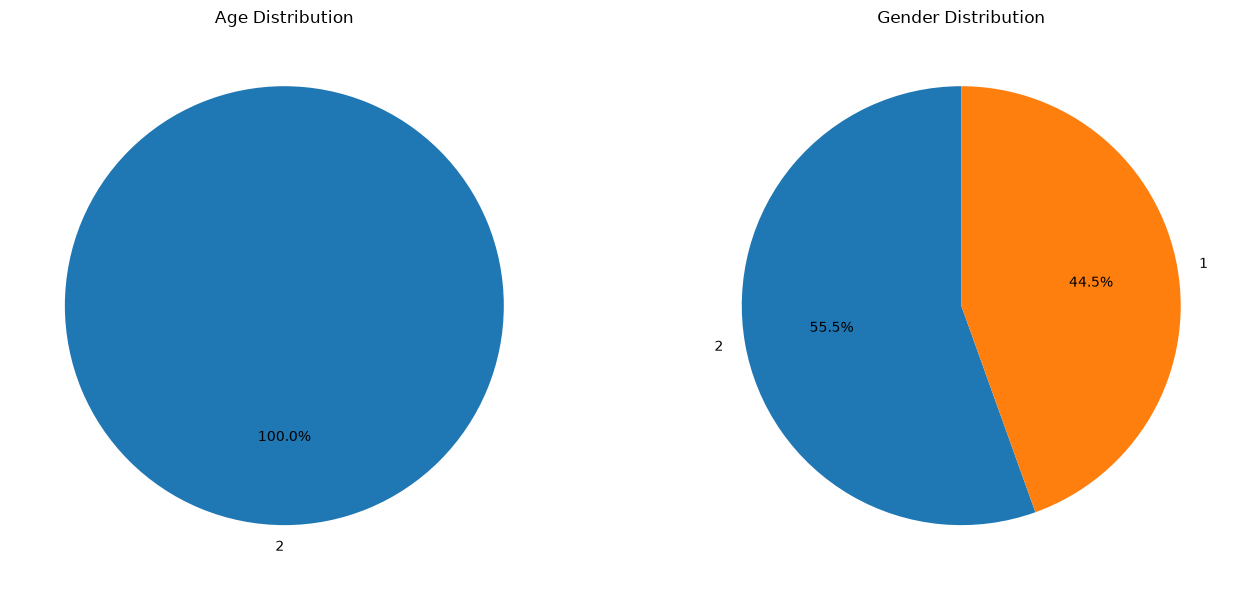

In [19]:
import matplotlib.pyplot as plt

age_counts = df['Age'].value_counts()
gender_counts = df['Gender'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].pie(age_counts, labels=age_counts.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Age Distribution')

axes[1].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Gender Distribution')

plt.tight_layout()
plt.show()

/var/folders/v6/v4q54r017v92tsdnk65qj8y00000gn/T/ipykernel_3259/1485812248.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Race', data=df, palette='viridis')


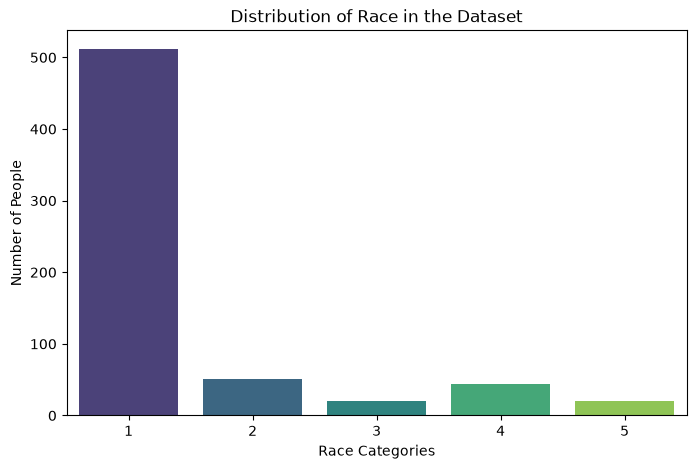

In [20]:
# Create a bar chart for Race distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='Race', data=df, palette='viridis')

# Add titles and labels
plt.title('Distribution of Race in the Dataset')
plt.xlabel('Race Categories')
plt.ylabel('Number of People')

# Show the plot
plt.show()

/var/folders/v6/v4q54r017v92tsdnk65qj8y00000gn/T/ipykernel_3259/55198082.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Trouble Sleeping', data=df_cleaned, palette='BrBG')


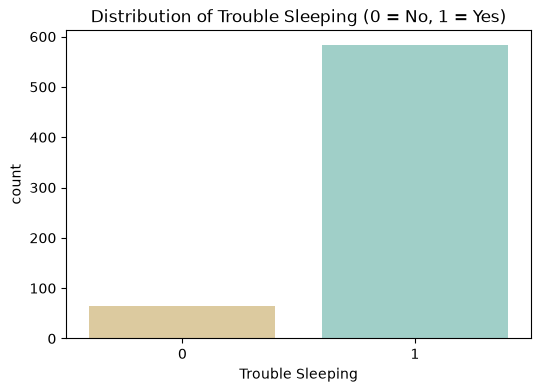

Trouble Sleeping
1    583
0     64
Name: count, dtype: int64


In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Target 
plt.figure(figsize=(6, 4))
sns.countplot(x='Trouble Sleeping', data=df_cleaned, palette='BrBG')
plt.title('Distribution of Trouble Sleeping (0 = No, 1 = Yes)')
plt.show()
print(df_cleaned['Trouble Sleeping'].value_counts())

/var/folders/v6/v4q54r017v92tsdnk65qj8y00000gn/T/ipykernel_3259/2516221928.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Gender', y='Trouble Sleeping', data=df_cleaned, palette='muted', split=True, inner="quart")


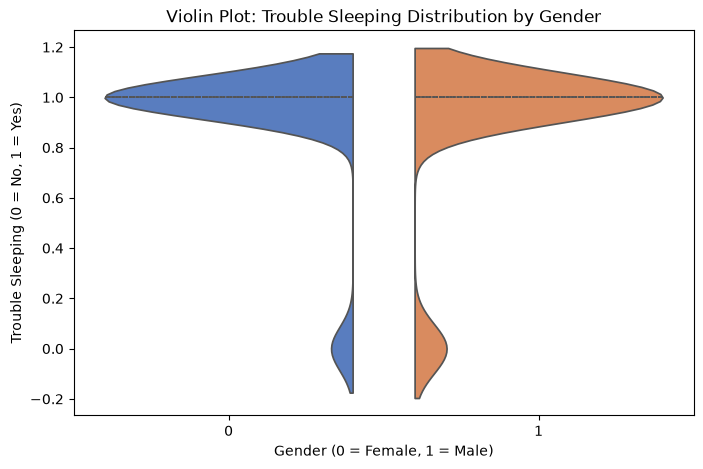

In [22]:
plt.figure(figsize=(8, 5))
# inner='quartile' 
sns.violinplot(x='Gender', y='Trouble Sleeping', data=df_cleaned, palette='muted', split=True, inner="quart")
plt.title('Violin Plot: Trouble Sleeping Distribution by Gender')
plt.xlabel('Gender (0 = Female, 1 = Male)')
plt.ylabel('Trouble Sleeping (0 = No, 1 = Yes)')
plt.show()

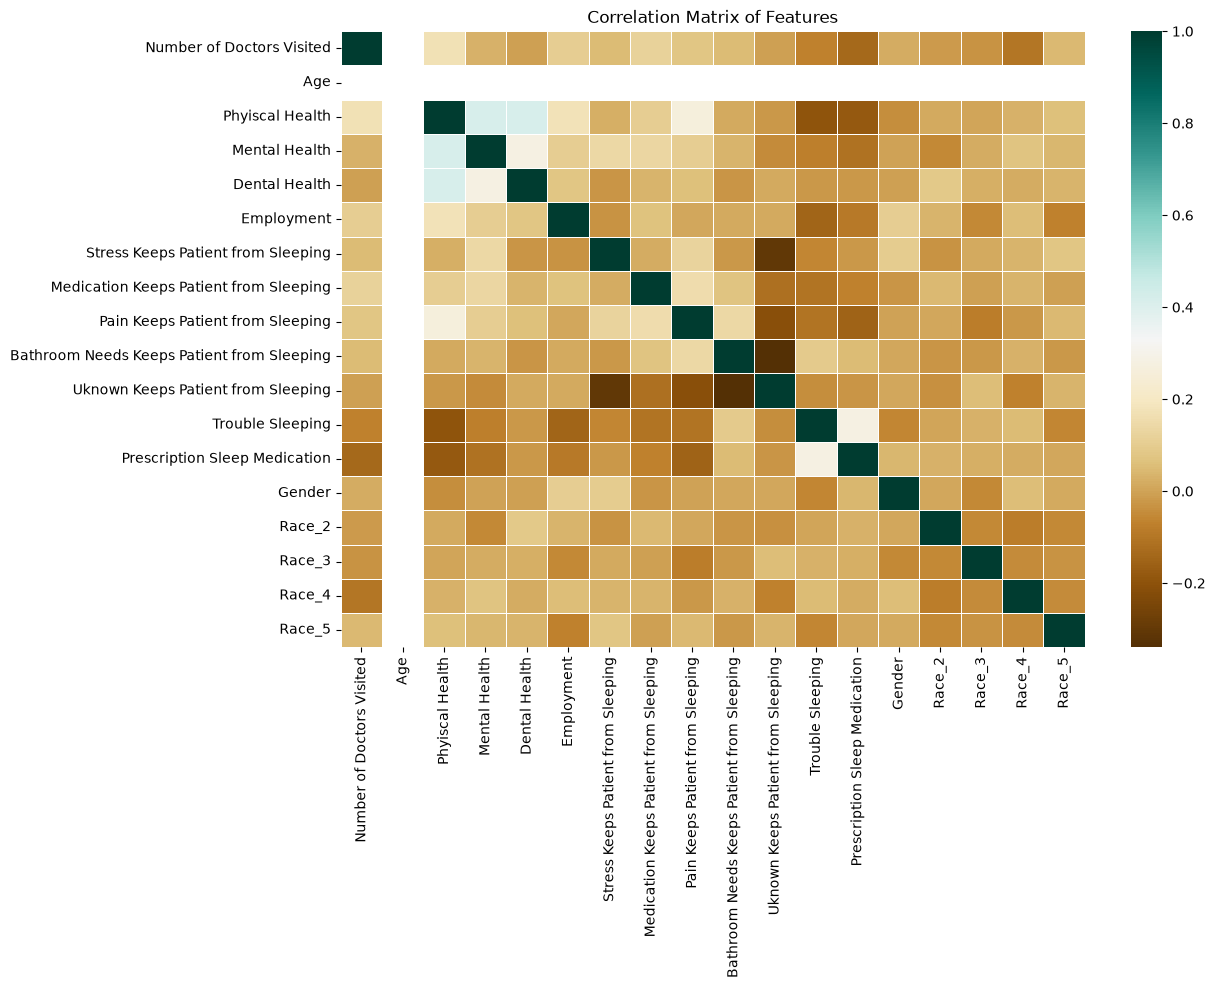

Trouble Sleeping                              1.000000
Prescription Sleep Medication                 0.282199
Bathroom Needs Keeps Patient from Sleeping    0.092601
Race_4                                        0.048373
Race_3                                        0.029264
Race_2                                        0.000861
Name: Trouble Sleeping, dtype: float64


In [23]:
plt.figure(figsize=(12, 8))
#
corr_matrix = df_cleaned.corr()
sns.heatmap(corr_matrix, annot=False, cmap='BrBG', linewidths=0.5)
plt.title('Correlation Matrix of Features')
plt.show()

# Trouble Sleeping-5 columns
print(corr_matrix['Trouble Sleeping'].sort_values(ascending=False).head(6))

# 4.Train/Test 

# 4.1 Y=X

In [24]:
from sklearn.model_selection import train_test_split

# 'Trouble Sleeping'- X 
X = df_cleaned.drop('Trouble Sleeping', axis=1)

# 'Trouble Sleeping' -y 
y = df_cleaned['Trouble Sleeping']

print("X:", X.shape)
print("y:", y.shape)

X: (647, 17)
y: (647,)


* Keeping the 'Trouble Sleeping' column separately in the y variable. y is the answer or target value that we want our model to predict. All the remaining variables become X. The algorithm cannot automatically distinguish between X and y, and we can change the target depending on the research question and objective. The goal of this research is to predict the factors that contribute to difficulty sleeping.

# 4.2 Train/Test (95:5, 85:15,75:25)

In [25]:
# 95:5
X_train_95, X_test_5, y_train_95, y_test_5 = train_test_split(X, y, test_size=0.20, random_state=42)

print("95:5")
print(f"Train size: {X_train_95.shape[0]}")
print(f"Test size:  {X_test_5.shape[0]}")

95:5
Train size: 517
Test size:  130


In [26]:
# 85:15 
# test_size=0.15 нь 15% test, 85% (train) 
X_train_85, X_test_15, y_train_85, y_test_15 = train_test_split(X, y, test_size=0.15, random_state=42)

print("85:15")
print(f"Train size: {X_train_85.shape[0]}")
print(f"Test size:  {X_test_15.shape[0]}")

85:15
Train size: 549
Test size:  98


In [27]:
# 3. 75:25 
# test_size=0.30 нь 30% тест, 70% сургалт (train) болно
X_train_75, X_test_25, y_train_75, y_test_25 = train_test_split(X, y, test_size=0.25, random_state=42)

print("75:25")
print(f"Train size: {X_train_75.shape[0]}")
print(f"Test size:  {X_test_25.shape[0]}")

75:25
Train size: 485
Test size:  162


* Conclusion: The data was divided into 3 parts: 95:5, 85:15, and 75:25, with the aim of testing "What amount of data will our model learn best and make correct predictions?" and increasing the reliability of the study.

# 4.3 Impact of Train/Test Split Ratios on Model Performance

In [28]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

* This code specifies the number of different models being utilized. Each model relies on a distinct algorithm to function effectively and accurately.

In [29]:
from sklearn.metrics import accuracy_score, classification_report
# 95:5
# Train and evaluate ML model classifiers for 'Trouble Sleeping'
results = []

for name, classifier in classifiers.items():
    # 1. Train the classifier using the 5 % training data
    classifier.fit(X_train_95, y_train_95)
    
    # 2. Predict on the 5% test set
    y_pred = classifier.predict(X_test_5)
    
    # 3. Calculate performance metrics
    accuracy = accuracy_score(y_test_5, y_pred)
    report = classification_report(y_test_5, y_pred, output_dict=True, zero_division=0)
    
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # 4. Append results to the list
    results.append([name, accuracy, precision, recall, f1_score])

# Display the results nicely (optional, but recommended)
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
print(df_results.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score
   k-Nearest Neighbors  0.892308   0.796213 0.892308  0.841526
         Random Forest  0.876923   0.827167 0.876923  0.845278
   Logistic Regression  0.900000   0.910078 0.900000  0.859320
Support Vector Machine  0.892308   0.796213 0.892308  0.841526


* 95:5. Logistic Regression can be seen to have a very high accuracy (90%) and reliability (F1 86%) in predicting "difficulty sleeping". It has shown the best results compared to other models (e.g. Random Forest 87%).An F1-score of 86% explains that the model is balanced and performs well, with a relatively low probability of making errors (mispredictions)

In [30]:
from sklearn.metrics import accuracy_score, classification_report
# 85:15
# Train and evaluate ML model classifiers for 'Trouble Sleeping'
results = []

for name, classifier in classifiers.items():
    # 1. Train the classifier using the 70% training data
    classifier.fit(X_train_85, y_train_85)
    
    # 2. Predict on the 15% test set
    y_pred = classifier.predict(X_test_15)
    
    # 3. Calculate performance metrics
    accuracy = accuracy_score(y_test_15, y_pred)
    report = classification_report(y_test_15, y_pred, output_dict=True,zero_division=0)
    
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # 4. Append results to the list
    results.append([name, accuracy, precision, recall, f1_score])

# Display the results nicely (optional, but recommended)
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
print(df_results.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score
   k-Nearest Neighbors  0.887755   0.788109 0.887755  0.834970
         Random Forest  0.877551   0.787082 0.877551  0.829858
   Logistic Regression  0.887755   0.788109 0.887755  0.834970
Support Vector Machine  0.887755   0.788109 0.887755  0.834970


* For the 85:15 ratio, the 3 models (k-NN, Logistic, SVM) perform equally well, with Random Forest lagging slightly behind.Random Forest Features: This model has slightly lower Precision (0.787) and Recall (0.877) than the other 3 models. However, if you remember that Random Forest had the highest Precision (0.827) on the previous 95:5, you can see that the behavior of the model also changes when the data partition changes.

In [31]:
from sklearn.metrics import accuracy_score, classification_report
# 75:25
# Train and evaluate ML model classifiers for 'Trouble Sleeping'
results = []

for name, classifier in classifiers.items():
    # 1. Train the classifier using the 75% training data
    classifier.fit(X_train_75, y_train_75)
    
    # 2. Predict on the 25 test set
    y_pred = classifier.predict(X_test_25)
    
    # 3. Calculate performance metrics
    accuracy = accuracy_score(y_test_25, y_pred)
    report = classification_report(y_test_25, y_pred, output_dict=True,zero_division=0)
    
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # 4. Append results to the list
    results.append([name, accuracy, precision, recall, f1_score])

# Display the results nicely (optional, but recommended)
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
print(df_results.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score
   k-Nearest Neighbors  0.882716   0.789510 0.882716  0.833515
         Random Forest  0.876543   0.821027 0.876543  0.840123
   Logistic Regression  0.901235   0.911111 0.901235  0.864327
Support Vector Machine  0.888889   0.790123 0.888889  0.836601


* For the 75:25 ratio, the Logistic Regression model is the most stable and performs well (Accuracy ~90%). The F1-score is 86.4%, outperforming the other 3 models.
* Conclusion:Although the Logistic Regression Accuracy (0.901) for the 75:25 split is slightly higher than that for the 95:5 split (0.900), the overall stability of the models and the performance of the other models suggest that the 95:5 split is more balanced and reliable.The current data set is 647 rows, which is relatively small, so 25% is only 162 rows. Using 75:25 on such a small data set is a bit risky.The Logistic Regression model shows the most consistent and high results in each division. Therefore, the final conclusion of your study is that "Logistic Regression is the most suitable and reliable model for predicting whether sleep is difficult.

# 5. Hyperparameter Tuning – GridSearchCV 

In [32]:
# 1. Logistic Regression 
lr_model = LogisticRegression(random_state=42, max_iter=1000)

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],     
    'solver': ['liblinear', 'lbfgs'],  
    'class_weight': ['balanced', None]  
}

# 3. GridSearchCV 
grid_search_lr = GridSearchCV(
    estimator=lr_model, 
    param_grid=param_grid_lr, 
    cv=5, 
    scoring='accuracy', 
    n_jobs=-1, 
    verbose=1
)

In [33]:
from sklearn.metrics import accuracy_score

# GridSearchCV-95:5 
print("GridSearchCV (Logistic Regression)")
grid_search_lr.fit(X_train_95, y_train_95)

#Cross-Validation
print("\n(Logistic Regression)")
print("Best Parameters:", grid_search_lr.best_params_)
print("Best Cross-Validation Accuracy:", round(grid_search_lr.best_score_, 4))

GridSearchCV (Logistic Regression)
Fitting 5 folds for each of 20 candidates, totalling 100 fits

(Logistic Regression)
Best Parameters: {'C': 0.1, 'class_weight': None, 'solver': 'lbfgs'}
Best Cross-Validation Accuracy: 0.9052


* Problem: Every machine learning algorithm has its own internal settings (hyperparameters), and if configured incorrectly, the model performs poorly. Solution: The goal is to automatically find the most optimal configuration that gives the model the highest accuracy, rather than doing it manually. 
* Methodology
• GridSearchCV: This is a "grid search" tool that tests all the possible configurations we provide, one by one.
• Cross-Validation (cv=5): By splitting the data into 5 parts for each test, it reduces errors caused by random chance and makes the results more reliable. 
* Parameters Tested
In the section named param_grid_lr in the code, a total of 20 different combinations (5 × 2 × 2) of the following 3 parameters are set to be tested:
• C (Regularization strength): The penalty strength to prevent the model from overfitting (0.01, 0.1, 1, 10, 100).
• solver: The mathematical algorithm used for computation (liblinear, lbfgs).
• class_weight: Handles class imbalance in the data (balanced, None). 
* Results
• Best Configuration: After 100 trials (20 combinations × 5 checks), the best one was identified as {'C': 0.1, 'class_weight': None, 'solver': 'lbfgs'}.
• Performance Improvement: Using this optimal configuration, the model's accuracy improved from the previous 90.0% to 90.52%. 
Conclusion:This code is the "Optimization" step that extracts the maximum capability from the model by fine-tuning it to its absolute best settings.

In [34]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

# train the Logistic Regression model
lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr.fit(X_train_95, y_train_95)
# 
importance = pd.Series(abs(lr.coef_[0]), index=X_train_95.columns).nlargest(5)

print("Top 5 Influential Features (Logistic Regression):\n")
print(importance)

Top 5 Influential Features (Logistic Regression):

Race_4                                    1.363998
Medication Keeps Patient from Sleeping    1.092495
Employment                                0.861126
Prescription Sleep Medication             0.841826
Phyiscal Health                           0.698229
dtype: float64


* What do the results indicate?
 
* The output at the bottom of the image shows the top 5 factors that have the highest influence on the likelihood of experiencing "Trouble Sleeping":
1. Race_4 (1.363998): Race/Ethnicity category 4 has the highest score. This indicates that, statistically, individuals in this specific demographic group have a higher probability of experiencing difficulty sleeping.
2. Medication Keeps Patient from Sleeping (1.092495): Medical treatment or the medication itself is preventing the patient from sleeping. This is a very logical and expected finding.
3. Employment (0.861126): Employment status. Having a job or work-related stress is shown to affect sleep patterns.
4. Prescription Sleep Medication (0.841826): Prescription sleeping pills. The use of sleep medication implies that these individuals already have an underlying sleep problem.
5. Physical Health (0.698229): Physical health condition. The poorer the physical health, the higher the likelihood of experiencing trouble sleeping.

In [35]:
best_lr = grid_search_lr.best_estimator_
y_pred_tuned_lr = best_lr.predict(X_test_5)

#  Accuracy
final_accuracy_lr = accuracy_score(y_test_5, y_pred_tuned_lr)

print(f" Beforev Accuracy (Logistic Regression): 90.52%")
print(f"After Accuracy (Logistic Regression): {round(final_accuracy_lr * 100, 2)}%")

 Beforev Accuracy (Logistic Regression): 90.52%
After Accuracy (Logistic Regression): 89.23%


* Final Verification: This code tests the model with the best parameters found by GridSearchCV on the unseen (test) dataset.
• Performance Drop: The accuracy slightly decreased from 90.52% during cross-validation to 89.23% on the actual test data.
• Significance: This minor drop is completely normal. It proves that the model is not overfitting and demonstrates stable, reliable performance on new data.

# 6. References

https://archive.ics.uci.edu/dataset/936/national+poll+on+healthy+aging+(npha)
David McQuaid (2026). How to Deal with Missing Data in Python [PDF document]. CCT College Dublin Moodle. https://moodle.cct.ie/course/view.php?id=3668

David McQuaid (2026). What is Exploratory Data Analysis [PDF document]. CCT College Dublin Moodle. https://moodle.cct.ie/course/view.php?id=3668 David McQuaid (2026). Lecture 6 - Unsupervised Learning [PDF document]. CCT College Dublin Moodle. https://moodle.cct.ie/course/view.php?id=3670

Muhammad Iqbal. (2026). Tutorial_6 PCA and KMeans [ZIP file]. CCT College Dublin Moodle. https://moodle.cct.ie/course/view.php?id=3670

Muhammad Iqbal. (2026). Data ReScaling [Course material]. CCT College Dublin Moodle. https://moodle.cct.ie/course/view.php?id=3670

Muhammad Iqbal. (2026). PCA interpretation [Course material]. CCT College Dublin Moodle. https://moodle.cct.ie/course/view.php?id=3670

Muhammad Iqbal. (2026). Overfitting and Underfitting [PDF document]. CCT College Dublin Moodle. https://moodle.cct.ie/course/view.php?id=3670